# **Explanation**

Sure! Let's go through the code with detailed explanations after each code snippet.

### 1. Import Libraries
```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import pickle
```
**Explanation:**
- `pandas`: For data manipulation and analysis.
- `numpy`: For numerical operations.
- `matplotlib.pyplot`: For plotting and visualization.
- `seaborn`: For statistical data visualization.
- `sklearn`: A machine learning library.
- `tensorflow`: For building and training neural networks.
- `pickle`: For saving Python objects to a file.

### 2. Load Data
```python
malData=pd.read_csv("/content/drive/MyDrive/Major Project/Copy of malwaredata (3).csv", sep="|", low_memory =True )
malData.head()
malData.shape
malData.describe()
```
**Explanation:**
- Loads the dataset from a CSV file into a pandas DataFrame named `malData`.
- The CSV file is read with a pipe `|` separator and `low_memory=True` to optimize memory usage.
- `malData.describe()` provides a statistical summary of the dataset, including count, mean, standard deviation, min, and max values for each column.

### 3. Split Data into Legitimate and Malicious
```python
legit = malData[0:41323].drop(["legitimate"], axis=1)
mal = malData[41323:].drop(["legitimate"], axis=1)
print("The shape of the legit dataset is: %s samples, %s features" % (legit.shape[0], legit.shape[1]))
print("The shape of the mal dataset is: %s samples, %s features" % (mal.shape[0], mal.shape[1]))
```
**Explanation:**
- Splits the dataset into two parts: `legit` (legitimate samples) and `mal` (malicious samples) based on index ranges.
- Drops the `legitimate` column from both parts.
- Prints the shape (number of samples and features) of both subsets.

### 4. Plot Histogram
```python
fig = plt.figure()
ax = fig.add_axes([0,0,1,1])
ax.hist(malData['legitimate'], 20)
plt.show()
```
**Explanation:**
- Creates a figure and an axis for plotting.
- Plots a histogram of the `legitimate` column to visualize the distribution of legitimate and malicious samples.
- Displays the plot.

### 5. Prepare Data for Modeling
```python
y = malData['legitimate']
malData = malData.drop(['legitimate', 'Name', 'md5'], axis=1)
print("The Name and md5 variables are removed successfully")
```
**Explanation:**
- Extracts the `legitimate` column into `y` to use as the target variable.
- Drops the `legitimate`, `Name`, and `md5` columns from `malData` as they are not needed for modeling.
- Prints a confirmation message indicating that the columns were removed.

### 6. Split Data into Training and Testing Sets
```python
X_train, X_test, y_train, y_test = train_test_split(malData, y, test_size=0.2, random_state=42)
```
**Explanation:**
- Splits the dataset into training and testing sets using an 80-20 split (`test_size=0.2`).
- `random_state=42` ensures reproducibility of the split.

### 7. Train Random Forest Classifier
```python
clf = RandomForestClassifier(max_depth=2, random_state=0)
randomModel = clf.fit(X_train, y_train)
```
**Explanation:**
- Initializes a Random Forest Classifier with a maximum depth of 2 and a fixed random state.
- Trains the model on the training data (`X_train`, `y_train`).

### 8. Evaluate Random Forest Model
```python
train_pred = randomModel.predict(X_train)
print("Training accuracy:", accuracy_score(y_train, train_pred))

prediction = randomModel.predict(X_test)
print("Testing accuracy:", accuracy_score(y_test, prediction))
print("F1 Score:", f1_score(y_test, prediction))
```
**Explanation:**
- Predicts the target variable for the training set and prints the training accuracy.
- Predicts the target variable for the test set and prints the testing accuracy and F1 score.

### 9. Plot Confusion Matrix for Random Forest
```python
cm = confusion_matrix(y_test, prediction)
titles_options = [("Confusion matrix, without normalization", None), ("Normalized confusion matrix", 'true')]

for title, normalize in titles_options:
    plt.figure(figsize=(6, 4))
    plt.title(title)

    if normalize == 'true':
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.show()
```
**Explanation:**
- Computes the confusion matrix for the test predictions.
- Plots two confusion matrices: one without normalization and one with normalization.
- Uses a heatmap to visualize the confusion matrices.

### 10. Save Random Forest Model
```python
pickle_data = {'randomModel': randomModel, 'legit': legit, 'mal': mal, 'malData': malData}

with open('/content/drive/MyDrive/Malware Project /RandomF_Model/model.pkl', 'wb') as file:
    pickle.dump(pickle_data, file)
```
**Explanation:**
- Prepares a dictionary containing the Random Forest model and data subsets.
- Saves the dictionary to a pickle file for later use.

### 11. Train Logistic Regression Model
```python
clf = LogisticRegression(random_state=0)
logModel = clf.fit(X_train, y_train)

train_log = logModel.predict(X_train)
print("Training accuracy:", accuracy_score(y_train, train_log))

pred = logModel.predict(X_test)
print("Testing accuracy:", accuracy_score(y_test, pred))
```
**Explanation:**
- Initializes and trains a Logistic Regression model.
- Predicts the target variable for the training and test sets, and prints their accuracies.

### 12. Plot Confusion Matrix for Logistic Regression
```python
cm = confusion_matrix(y_test, pred)
titles_options = [("Confusion matrix, without normalization", None), ("Normalized confusion matrix", 'true')]

for title, normalize in titles_options:
    plt.figure(figsize=(6, 4))
    plt.title(title)

    if normalize == 'true':
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.show()
```
**Explanation:**
- Computes and plots confusion matrices for the Logistic Regression model, both without and with normalization.

### 13. Define and Train Neural Network Model
```python
model = Sequential()
model.add(Dense(128, input_dim=54, activation="relu"))
model.add(Dense(64, activation="relu"))
model.add(Dense(32, activation="relu"))
model.add(Dense(1, activation='sigmoid'))
model.summary()
model.compile(loss="binary_crossentropy", optimizer="rmsprop", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=5, batch_size=32)
```
**Explanation:**
- Defines a neural network model with three hidden layers and one output layer.
- Prints the model summary.
- Compiles the model with binary cross-entropy loss and RMSProp optimizer.
- Trains the model on the training data for 5 epochs with a batch size of 32.

### 14. Evaluate Neural Network Model
```python
trainPred = model.predict(X_train)
trainPred = [1 if y >= 0.5 else 0 for y in trainPred]
print("Training accuracy:", accuracy_score(y_train, trainPred))

y_prediction = model.predict(X_test)
y_prediction = [1 if y >= 0.5 else 0 for y in y_prediction]
print("Testing accuracy:", accuracy_score(y_test, y_prediction))
```
**Explanation:**
- Predicts the target variable for the training set and converts the predictions to binary labels.
- Prints the training accuracy.
- Predicts the target variable for the test set, converts the predictions to binary labels, and prints the testing accuracy.

### 15. Plot Confusion Matrix for Neural Network
```python
cm = confusion_matrix(y_test, y_prediction)
titles_options = [("Confusion matrix, without normalization", None), ("Normalized confusion matrix", 'true')]

for title, normalize in titles_options:
    plt.figure(figsize=(6, 4))
    plt.title(title)

    if normalize == 'true':
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.show()
```
**Explanation:**
- Computes and plots confusion matrices for the neural network model, both without and with normalization.

### 16. Define Keras Model Wrapper
```python


class KerasClassifierWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, model):
        self.model = model

    def fit(self, X, y, **kwargs):
        self.model.fit(X, y, **kwargs)
        return self

    def predict(self, X):
        return np.round(self.model.predict(X))

    def predict_proba(self, X):
        return np.column_stack((1 - self.model.predict(X), self.model.predict(X)))
```
**Explanation:**
- Defines a wrapper class to make the Keras model compatible with scikit-learn.
- Implements `fit`, `predict`, and `predict_proba` methods to allow the Keras model to be used in scikit-learn pipelines and ensembles.

### 17. Define Neural Network Model
```python
neural_network = Sequential()
neural_network.add(Dense(128, input_dim=54, activation="relu"))
neural_network.add(Dense(64, activation="relu"))
neural_network.add(Dense(32, activation="relu"))
neural_network.add(Dense(1, activation="sigmoid"))
neural_network.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
keras_model_wrapper = KerasClassifierWrapper(neural_network)
```
**Explanation:**
- Defines a neural network model with three hidden layers and one output layer.
- Compiles the model with the Adam optimizer and binary cross-entropy loss.
- Wraps the Keras model with the custom wrapper class to make it compatible with scikit-learn.



# **Explanation Ends here**

#**Actual Project Implementation Starts here**

# Importing libraires

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Exploring the malware dataset.

In [ ]:
malData=pd.read_csv("/content/drive/MyDrive/Major Project/Copy of malwaredata (3).csv", sep="|", low_memory =True )

In [ ]:
malData.head()

,Name,md5,Machine,SizeOfOptionalHeader,Characteristics,MajorLinkerVersion,MinorLinkerVersion,SizeOfCode,SizeOfInitializedData,SizeOfUninitializedData,...,ResourcesNb,ResourcesMeanEntropy,ResourcesMinEntropy,ResourcesMaxEntropy,ResourcesMeanSize,ResourcesMinSize,ResourcesMaxSize,LoadConfigurationSize,VersionInformationSize,legitimate
0,memtest.exe,631ea355665f28d4707448e442fbf5b8,332,224,258,9,0,361984,115712,0,...,4,3.262823,2.568844,3.537939,8797.000000,216,18032,0,16,1
1,ose.exe,9d10f99a6712e28f8acd5641e3a7ea6b,332,224,3330,9,0,130560,19968,0,...,2,4.250461,3.420744,5.080177,837.000000,518,1156,72,18,1
2,setup.exe,4d92f518527353c0db88a70fddcfd390,332,224,3330,9,0,517120,621568,0,...,11,4.426324,2.846449,5.271813,31102.272727,104,270376,72,18,1
3,DW20.EXE,a41e524f8d45f0074fd07805ff0c9b12,332,224,258,9,0,585728,369152,0,...,10,4.364291,2.669314,6.400720,1457.000000,90,4264,72,18,1
4,dwtrig20.exe,c87e561258f2f8650cef999bf643a731,332,224,258,9,0,294912,247296,0,...,2,4.306100,3.421598,5.190603,1074.500000,849,1300,72,18,1


In [ ]:
malData.shape

(138047, 57)

In [ ]:
malData.describe()

,Machine,SizeOfOptionalHeader,Characteristics,MajorLinkerVersion,MinorLinkerVersion,SizeOfCode,SizeOfInitializedData,SizeOfUninitializedData,AddressOfEntryPoint,BaseOfCode,...,ResourcesNb,ResourcesMeanEntropy,ResourcesMinEntropy,ResourcesMaxEntropy,ResourcesMeanSize,ResourcesMinSize,ResourcesMaxSize,LoadConfigurationSize,VersionInformationSize,legitimate
count,138047.000000,138047.000000,138047.000000,138047.000000,138047.000000,1.380470e+05,1.380470e+05,1.380470e+05,1.380470e+05,1.380470e+05,...,138047.000000,138047.000000,138047.000000,138047.000000,1.380470e+05,1.380470e+05,1.380470e+05,1.380470e+05,138047.000000,138047.000000
mean,4259.069274,225.845632,4444.145994,8.619774,3.819286,2.425956e+05,4.504867e+05,1.009525e+05,1.719561e+05,5.779845e+04,...,22.050700,4.000127,2.434541,5.521610,5.545093e+04,1.818082e+04,2.465903e+05,4.656750e+05,12.363115,0.299340
std,10880.347245,5.121399,8186.782524,4.088757,11.862675,5.754485e+06,2.101599e+07,1.635288e+07,3.430553e+06,5.527658e+06,...,136.494244,1.112981,0.815577,1.597403,7.799163e+06,6.502369e+06,2.124860e+07,2.608987e+07,6.798878,0.457971
min,332.000000,224.000000,2.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,332.000000,224.000000,258.000000,8.000000,0.000000,3.020800e+04,2.457600e+04,0.000000e+00,1.272100e+04,4.096000e+03,...,5.000000,3.458505,2.178748,4.828706,9.560000e+02,4.800000e+01,2.216000e+03,0.000000e+00,13.000000,0.000000
50%,332.000000,224.000000,258.000000,9.000000,0.000000,1.136640e+05,2.631680e+05,0.000000e+00,5.288300e+04,4.096000e+03,...,6.000000,3.729824,2.458492,5.317552,2.708154e+03,4.800000e+01,9.640000e+03,7.200000e+01,15.000000,0.000000
75%,332.000000,224.000000,8226.000000,10.000000,0.000000,1.203200e+05,3.850240e+05,0.000000e+00,6.157800e+04,4.096000e+03,...,13.000000,4.233051,2.696833,6.502239,6.558429e+03,1.320000e+02,2.378000e+04,7.200000e+01,16.000000,1.000000
max,34404.000000,352.000000,49551.000000,255.000000,255.000000,1.818587e+09,4.294966e+09,4.294941e+09,1.074484e+09,2.028711e+09,...,7694.000000,7.999723,7.999723,8.000000,2.415919e+09,2.415919e+09,4.294903e+09,4.294967e+09,26.000000,1.000000


In [ ]:
legit= malData[0:41323].drop(["legitimate"], axis=1)
mal= malData[41323::].drop(["legitimate"], axis=1)
print("The shape of the legit dataset is: %s samples, %s features"%(legit.shape[0],legit.shape[1]))
print("The shape of the mal dataset is: %s samples, % s features" %(mal.shape[0],mal.shape[1]))

The shape of the legit dataset is: 41323 samples, 56 features
The shape of the mal dataset is: 96724 samples, 56 features


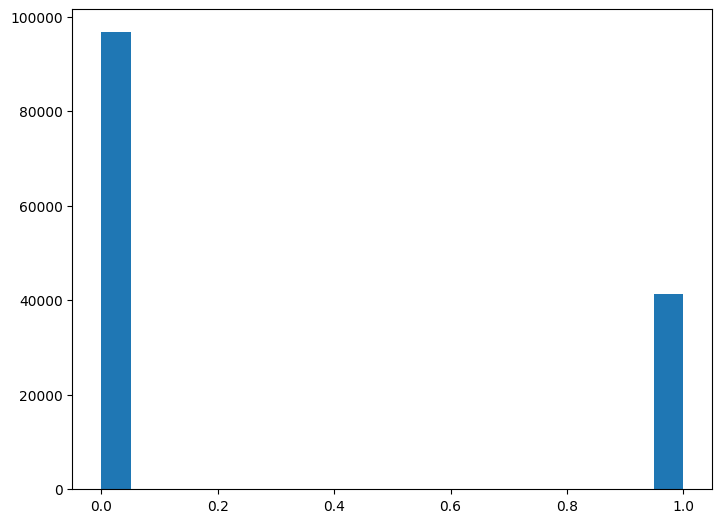

In [ ]:
fig = plt.figure()
ax = fig.add_axes([0,0,1,1])
ax.hist(malData['legitimate'],20)
plt.show()

# Data Cleaning

In [ ]:
y=malData['legitimate']
malData=malData.drop(['legitimate'],axis=1)

In [ ]:
malData=malData.drop(['Name'],axis=1)
malData=malData.drop(['md5'],axis=1)
print(" The Name and md5 variables are removed successfully")

 The Name and md5 variables are removed successfully


# Spliting the dataset into test and train

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(malData,y, test_size=0.2, random_state=42)

In [ ]:
X_train.shape

(110437, 54)

# Model Building

# 1- Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.datasets import make_classification

clf = RandomForestClassifier(max_depth=2, random_state=0)

randomModel=clf.fit(X_train, y_train)

## Random forest Evaluation on test data

In [ ]:
from sklearn.metrics import f1_score,accuracy_score,auc,confusion_matrix

In [ ]:
sklearn.metrics.ConfusionMatrixDisplay

sklearn.metrics._plot.confusion_matrix.ConfusionMatrixDisplay

In [ ]:
#  Accuracy on the train dataset

train_pred=randomModel.predict(X_train)

accuracy_score(y_train,train_pred)

0.9828318407780001

In [ ]:
# Accuracy on the test dataset

prediction=randomModel.predict(X_test)

accuracy_score(y_test,prediction)

0.9838102136906918

In [ ]:
f1_score(y_test, prediction)

0.9730933606212002

[[19080   170]
 [  277  8083]]


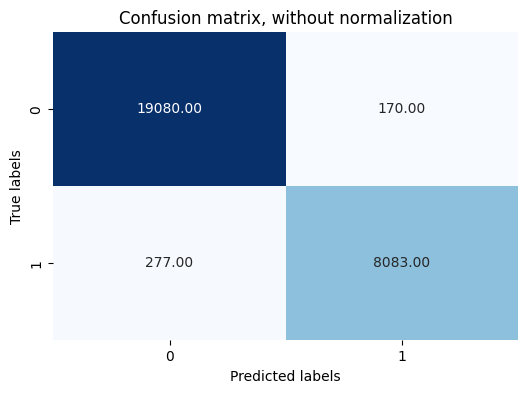

[[19080   170]
 [  277  8083]]


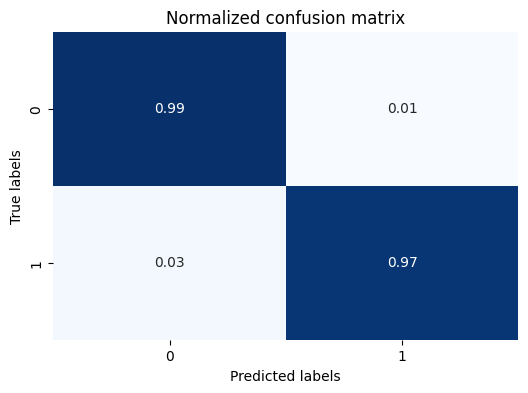

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming randomModel is your trained model and X_test, y_test are your test data
# Replace 'legitimate' with your actual class labels

# Get predictions from the model
y_pred = randomModel.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", 'true')
]

for title, normalize in titles_options:
    plt.figure(figsize=(6, 4))
    plt.title(title)

    if normalize == 'true':
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)

    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    print(confusion_matrix(y_test, y_pred))
    plt.show()

# 2 - logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(random_state=0)

logModel=clf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Model Evaluation

In [ ]:
# Accuracy on the train dataset

train_log= logModel.predict(X_train)

accuracy_score(y_train,train_log)

0.9547524833162798

In [ ]:
# Accuracy on the test dataset

pred=logModel.predict(X_test)

accuracy_score(y_test,pred)


0.9555595798623687

In [ ]:
f1_score(y_test, pred)

0.9221100742715673

[[19120   130]
 [ 1097  7263]]


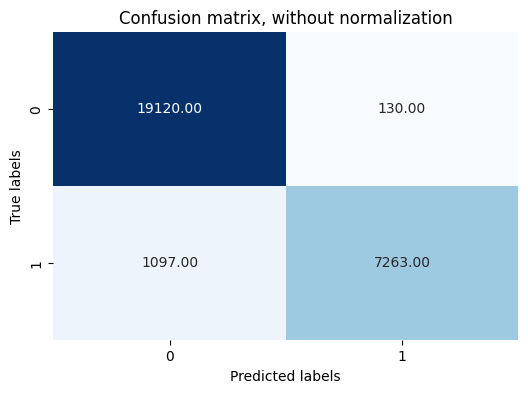

[[19120   130]
 [ 1097  7263]]


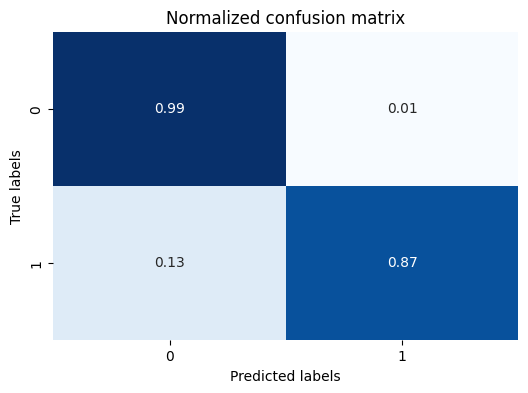

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming randomModel is your trained model and X_test, y_test are your test data
# Replace 'legitimate' with your actual class labels

# Get predictions from the model
y_pred = logModel.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", 'true')
]

for title, normalize in titles_options:
    plt.figure(figsize=(6, 4))
    plt.title(title)

    if normalize == 'true':
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)

    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    print(confusion_matrix(y_test, y_pred))
    plt.show()



# 3- Neural Network

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense

In [ ]:
# Define model
model = Sequential()
model.add(Dense(128, input_dim=54, activation= "relu")) # input layer
model.add(Dense(64, activation= "relu"))  # hidden layers
model.add(Dense(32, activation= "relu"))
model.add(Dense(1, activation='sigmoid')) ## output layer
model.summary() #Print model Summary

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,409 (68.00 KB)

 Trainable params: 17,409 (68.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile model
model.compile(loss= "binary_crossentropy" , optimizer="rmsprop", metrics=["accuracy"])

In [ ]:
# Fit Model
model.fit(X_train, y_train, epochs=5, batch_size=32)

Epoch 1/5
3452/3452 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - accuracy: 0.9429 - loss: 77102168.0000
Epoch 2/5
3452/3452 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9434 - loss: 43356288.0000
Epoch 3/5
3452/3452 ━━━━━━━━━━━━━━━━━━━━ 15s 4ms/step - accuracy: 0.9436 - loss: 26312350.0000
Epoch 4/5
3452/3452 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9476 - loss: 17931430.0000
Epoch 5/5
3452/3452 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9456 - loss: 9588086.0000


## Model evaluation

In [ ]:
  # Accuracy on the training dataset
trainPred=model.predict(X_train)

trainPred=[1 if y>= 0.5 else 0   for y in trainPred]

accuracy_score(y_train,trainPred)

3452/3452 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step


0.9745284641922544

In [ ]:
# Accuracy on the test dataset
y_prediction=model.predict(X_test)

y_prediction=[1 if y>= 0.5 else 0   for y in y_prediction]

accuracy_score(y_test, y_prediction)

863/863 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


0.9753350235421948

In [ ]:
f1_score(y_test,y_prediction)

0.9602103418054339

863/863 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


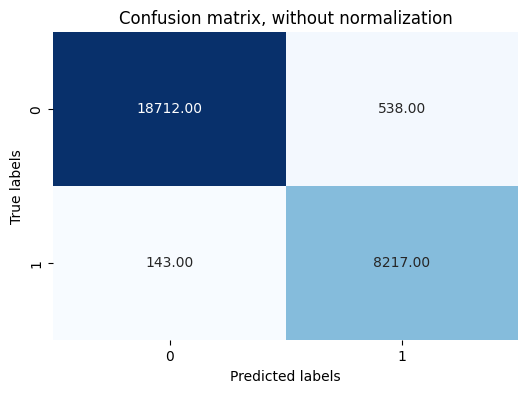

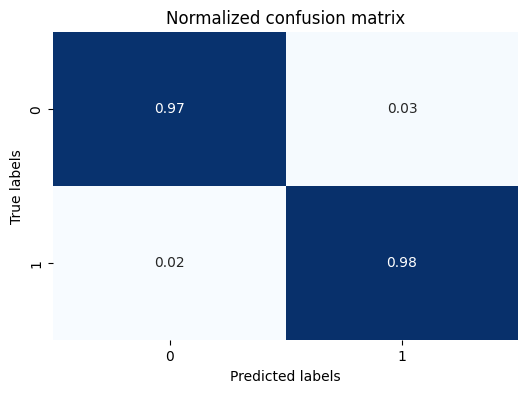

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming model is your trained model and X_test, y_test are your test data
# Replace 'legitimate' with your actual class labels

# Get predictions from the model
y_pred = model.predict(X_test)

# Convert predicted values to binary (0 or 1) based on a threshold
threshold = 0.5  # Adjust this threshold based on your classification problem
y_pred_binary = (y_pred > threshold).astype(int)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_binary)

# Plot the confusion matrix
titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", 'true')
]

for title, normalize in titles_options:
    plt.figure(figsize=(6, 4))
    plt.title(title)

    if normalize == 'true':
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)

    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')

    plt.show()


In [ ]:
confusion_matrix(y_test,y_prediction)

array([[18712,   538],
       [  143,  8217]])